<a href="https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/03_grpo_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Train Your RL Agent** · [Ch 1 · Q-learning](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) → [Ch 2 · REINFORCE](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb) → **📍 Ch 3 · GRPO** → [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

# 👥 Chapter 3 · GRPO: learn by comparing attempts

### The big idea

> **Ask the agent to try the same task several times. Compare the rewards. Make the successful choices more likely and the unsuccessful ones less likely.**

That's **GRPO** (*Group Relative Policy Optimization*). It was introduced in the [DeepSeekMath paper](https://arxiv.org/abs/2402.03300) and later used to train **DeepSeek-R1**.

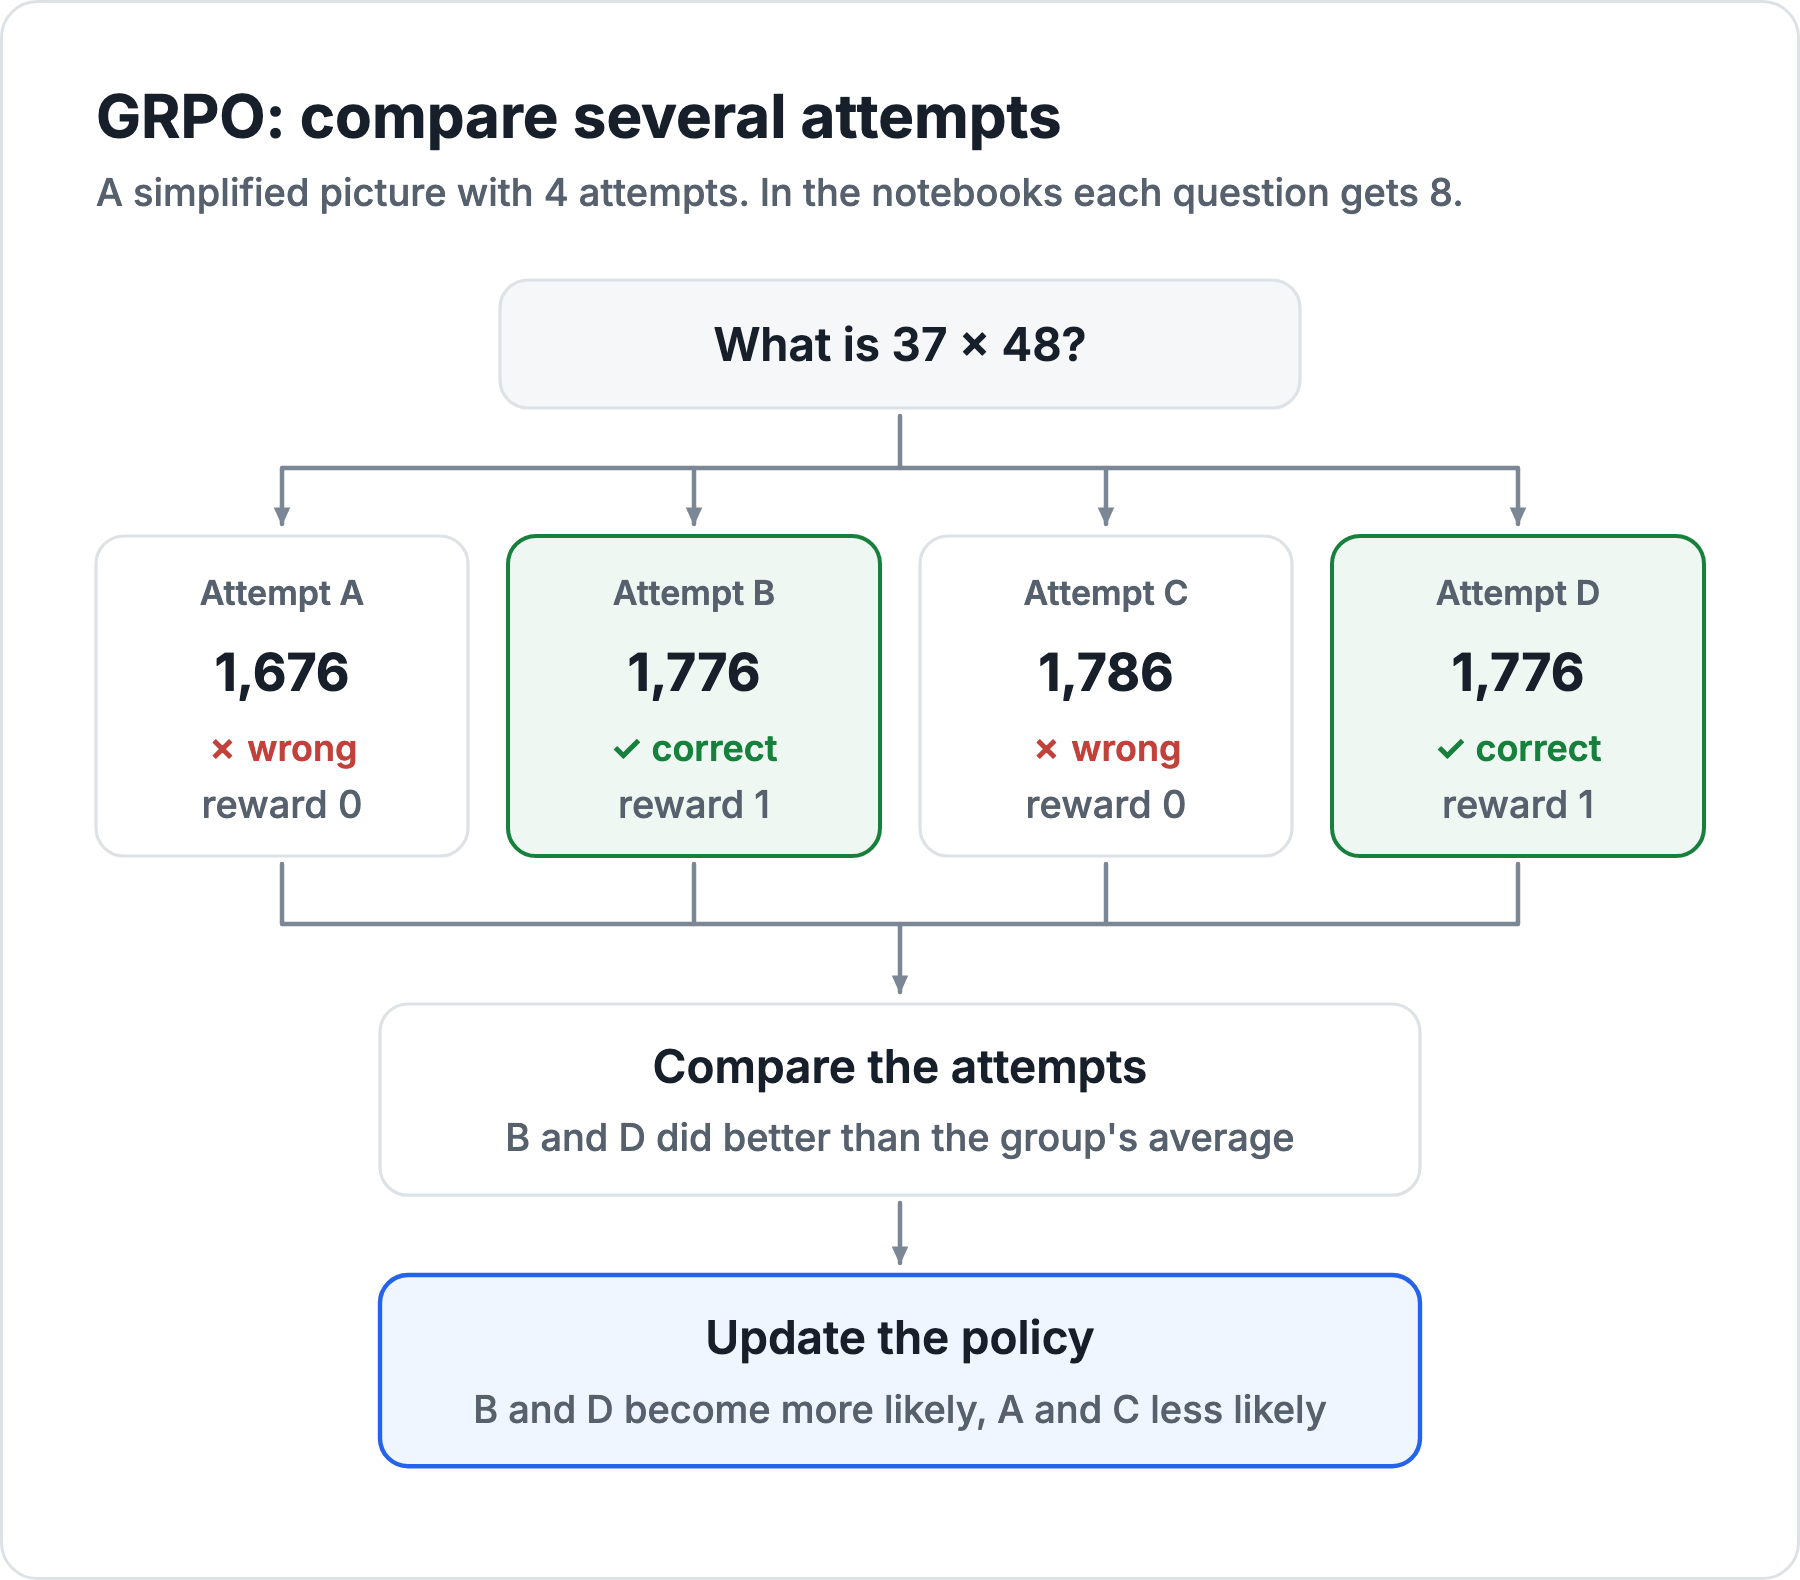

The picture shows 4 attempts to keep it simple. In this notebook each question gets **8**.

GRPO improves on REINFORCE (Chapter 2) with three ideas. We'll build each one separately:

| Idea | In one sentence |
|:--|:--|
| 👥 **Compare a group** | Judge each attempt against other attempts at the *same* question. |
| ✂️ **Small steps** | Learn from each batch a few times, but never change too much at once. |
| 🪢 **A leash** | Stay reasonably close to the starting brain. |

There's one more upgrade, which brings us closer to LLMs: 📖 **the agent now reads the question**. It gets no topic label, only the words.

✅ Free CPU · ✅ About 2 minutes · ✅ PyTorch only

## 1 · The world, now with real sentences 🌍

Same buttons, tools and rewards as before. The questions now come in **different phrasings** ("What is 3 x 4?", "Multiply 6 by 8", "Calculate 5 times 7"...).

In [1]:
import copy
import random
import re
import statistics

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
ACCENT, GREY, GOOD, BAD = "#2563EB", "#9AA4AE", "#16803C", "#C2413A"   # course colors

buttons = ["Calculator", "Dictionary", "Reply", "Finish"]

In [2]:
meanings = {
    "orbit": "a path around another object",
    "habitat": "an animal's natural home",
    "planet": "a large body orbiting a star",
    "volcano": "a mountain that erupts lava",
    "gravity": "a force pulling things together",
    "comet": "an icy body with a glowing tail",
}
greetings = {"hello": "Hello!", "thanks": "You're welcome!", "bye": "Goodbye!"}

def use_tool(button, task):
    kind, question, data = task
    if button == "Calculator" and kind == "math":
        return str(data[0] * data[1])
    if button == "Dictionary" and kind == "words":
        return meanings[data]
    if button == "Reply" and kind == "chat":
        return greetings[data]
    return None  # Wrong tool: no answer

In [3]:
practice = [
    ("math", "What is 3 x 4?", (3, 4)),
    ("math", "Multiply 6 by 8", (6, 8)),
    ("math", "Calculate 5 times 7", (5, 7)),
    ("math", "What is 12 x 2?", (12, 2)),
    ("words", "Define orbit", "orbit"),
    ("words", "What does habitat mean?", "habitat"),
    ("words", "Meaning of planet", "planet"),
    ("words", "Define volcano", "volcano"),
    ("chat", "Say hello", "hello"),
    ("chat", "Say thanks to my teacher", "thanks"),
    ("chat", "Please say bye", "bye"),
    ("chat", "Say hello to everyone", "hello"),
]
test_tasks = [  # new numbers, new words, new phrasings
    ("math", "What is 9 x 11?", (9, 11)),
    ("math", "Calculate 4 times 25", (4, 25)),
    ("words", "Define gravity", "gravity"),
    ("words", "What does comet mean?", "comet"),
    ("chat", "Say bye to my friend", "bye"),
    ("chat", "Say thanks", "thanks"),
]

Each task still carries its topic (`"math"`), but **only the world uses it**, so the calculator knows what to compute. The **agent never sees it**: it gets only the words.

Watch out for the trap: *"What is 9 x 11?"* (math) and *"What does comet mean?"* (words) both start with **"What"**. The agent has to learn which words actually matter.

## 2 · Teach the agent to read 📖

LLMs chop text into **tokens** and give each token an id number. We'll do the simplest version: **one token per word**. Words the agent has never seen become `<unk>` (unknown).

In [4]:
def words(text):
    return re.findall(r"[a-z]+|\d+", text.lower())

vocab = {"<unk>": 0}
for _, question, _ in practice:
    for w in words(question):
        vocab.setdefault(w, len(vocab))

def encode(question, has_answer):
    ids = torch.tensor([vocab.get(w, 0) for w in words(question)])
    return ids, torch.tensor([float(has_answer)])

print("Vocabulary size:", len(vocab))
print("'What does comet mean?' ->", encode("What does comet mean?", False)[0].tolist())

Vocabulary size: 34
'What does comet mean?' -> [1, 18, 0, 20]


**What just happened?** Every practice word got an id number. `comet` never appears in practice, so it became `0` (`<unk>`). The agent will simply **ignore** unknown words and rely on *"what"*, *"does"* and *"mean"*.

## 3 · A tiny neural network that reads (our "mini-LLM") 🧠

The brain is now a small **neural network**:

1. Each word gets a list of 16 numbers called an **embedding**. We average them into one "meaning of the question" and leave unknown words out.
2. We add one extra number: **1** if the agent already has an answer, **0** if not.
3. A small network turns that into 4 preferences, and softmax turns those into probabilities, just like Chapter 2.

An LLM does the same thing at enormous scale: tokens in, a probability for every possible next token out.

In [5]:
class TinyPolicy(nn.Module):
    def __init__(self, vocab_size, dim=16, n_actions=4):
        super().__init__()
        self.embed = nn.EmbeddingBag(vocab_size, dim, mode="mean", padding_idx=0)  # unknown words are ignored
        self.head = nn.Sequential(nn.Linear(dim + 1, 32), nn.Tanh(), nn.Linear(32, n_actions))

    def forward(self, observation):
        ids, has_answer = observation
        meaning = self.embed(ids[None])[0]
        return self.head(torch.cat([meaning, has_answer]))  # 4 preferences

policy = TinyPolicy(len(vocab))
print("Number of learnable numbers:", sum(p.numel() for p in policy.parameters()))
probs = torch.softmax(policy(encode("What is 9 x 11?", False)), -1)
print("Untrained probabilities:", {b: f"{p:.0%}" for b, p in zip(buttons, probs.tolist())})

Number of learnable numbers: 1252
Untrained probabilities: {'Calculator': '35%', 'Dictionary': '19%', 'Reply': '21%', 'Finish': '25%'}


**What just happened?** The network has about a thousand learnable numbers. Before training, its probabilities are close to random. Qwen2.5-0.5B, the LLM in Chapter 4, has hundreds of thousands of times more numbers, but the idea is the same.

## 4 · Play an episode 🎮

`play` runs one episode and records what the agent **saw** and what it **did**. We need both later to recompute the probabilities.

In [6]:
def play(policy, task, greedy=False):
    question, has_answer = task[1], False
    observations, actions, total_reward = [], [], 0.0
    for move in range(4):
        obs = encode(question, has_answer)
        with torch.no_grad():
            logits = policy(obs)
        if greedy:
            a = int(logits.argmax())
        else:
            a = int(torch.distributions.Categorical(logits=logits).sample())
        observations.append(obs)
        actions.append(a)

        if buttons[a] == "Finish":
            points, done = (1.0 if has_answer else -1.0), True
        else:
            done = False
            if use_tool(buttons[a], task) is not None:
                points, has_answer = -0.02, True
            else:
                points = -0.15
        if move == 3 and not done:
            points -= 0.5  # Running out of moves is bad
        total_reward += points
        if done:
            break
    return {"obs": observations, "actions": actions,
            "reward": total_reward, "success": bool(done and has_answer)}

In [7]:
attempt = play(policy, practice[0])
print("Question:", practice[0][1])
print("Buttons :", [buttons[a] for a in attempt["actions"]])
print(f"Reward  : {attempt['reward']:+.2f}")

Question: What is 3 x 4?
Buttons : ['Dictionary', 'Finish']
Reward  : -1.15


## 5 · Idea 1: compare a group of attempts 👥

Instead of comparing an attempt with a running average over *all* questions (Chapter 2), GRPO lets the agent try **the same question 8 times** and compares the attempts **with each other**:

- An attempt that did **better than its siblings** gets reinforced.
- One that did **worse** gets discouraged.
- If **all** the attempts scored the same, there is nothing to learn from that question.

How much better or worse an attempt did is again called its **advantage**. In GRPO it is measured *relative to the group*:

$$A_i = \frac{r_i - \text{mean of the group's rewards}}{\text{spread of the group's rewards}}$$

- $r_i$ is the reward of attempt $i$.
- Subtracting the **mean** makes above-average attempts positive and below-average ones negative.
- Dividing by the **spread** (the standard deviation) puts every question on the same scale, whether its rewards are big or small.

In [8]:
def group_advantages(rewards):
    rewards = torch.tensor(rewards)
    return (rewards - rewards.mean()) / (rewards.std() + 1e-4)   # 1e-4 avoids dividing by zero

### A worked example: one question, 8 attempts

In [9]:
G = 8
task = practice[0]
group = [play(policy, task) for _ in range(G)]
rewards = [g["reward"] for g in group]
advantages = group_advantages(rewards)
print(f"Question: {task[1]}   (group average reward: {sum(rewards) / G:+.2f})\n")
for i, (g, adv) in enumerate(zip(group, advantages)):
    path = " → ".join(buttons[a] for a in g["actions"])
    print(f"attempt {i + 1}: reward {g['reward']:+.2f} | advantage {adv:+.2f} | {path}")

Question: What is 3 x 4?   (group average reward: -0.73)

attempt 1: reward -1.00 | advantage -0.39 | Finish
attempt 2: reward -0.97 | advantage -0.34 | Reply → Calculator → Dictionary → Dictionary
attempt 3: reward -1.00 | advantage -0.39 | Finish
attempt 4: reward +0.96 | advantage +2.40 | Calculator → Calculator → Finish
attempt 5: reward -0.71 | advantage +0.03 | Dictionary → Calculator → Calculator → Calculator
attempt 6: reward -1.30 | advantage -0.81 | Dictionary → Reply → Finish
attempt 7: reward -0.97 | advantage -0.34 | Dictionary → Reply → Reply → Calculator
attempt 8: reward -0.84 | advantage -0.16 | Calculator → Reply → Calculator → Reply


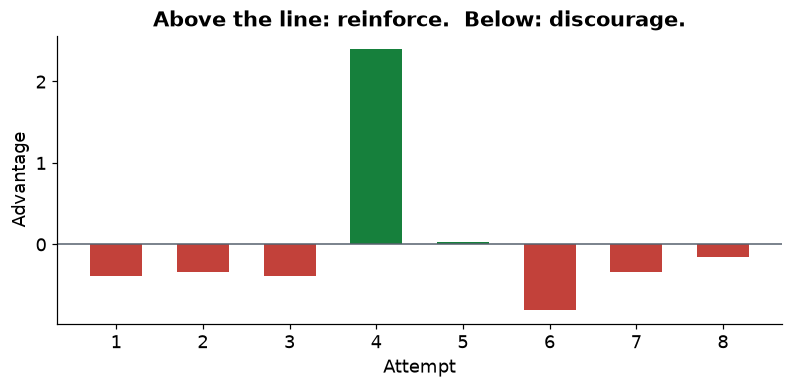

In [10]:
plt.figure(figsize=(8.5, 3.4))
plt.bar(range(1, G + 1), advantages, color=[GOOD if a > 0 else BAD for a in advantages], width=0.6)
plt.axhline(0, color="#56616D", linewidth=1)
plt.xlabel("Attempt")
plt.ylabel("Advantage")
plt.title("Above the line: reinforce.  Below: discourage.")
plt.show()

**What just happened?** The untrained agent mostly pressed the wrong buttons. The rare attempt that went **Calculator → … → Finish** scored far above its siblings, so it has a large **positive** advantage (green). Training will make exactly those choices more likely.

💡 No extra "critic" network is needed to guess what "usual" means: the group itself is the baseline. That saves a whole second model, which is why GRPO is popular for LLMs.

## 6 · Idea 2: take small, safe steps ✂️

To get more out of each batch of attempts, GRPO learns from it **several times** (several *epochs*). After the first update, though, the brain has changed, so the batch now comes from a slightly older brain. Pushing hard on old data can overshoot.

The fix: **once a choice has become a bit more (or less) likely, stop pushing it in that direction.**

We measure "how much has this choice changed?" with a **ratio**:

- ratio = (new probability of the choice) ÷ (old probability)
- ratio **1.0** means no change yet, and **1.3** means 30% more likely than before.

GRPO only lets the ratio move inside a safe zone, **0.8 to 1.2**. This is called **clipping**.

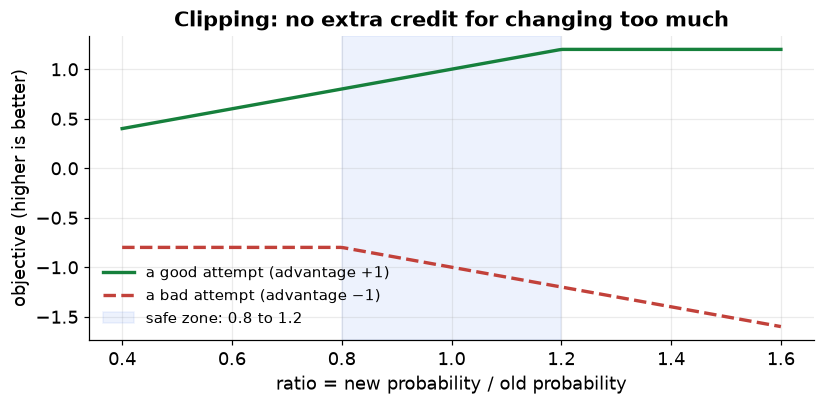

In [11]:
def clipped_objective(ratio, advantage, clip=0.2):
    return torch.min(ratio * advantage, ratio.clamp(1 - clip, 1 + clip) * advantage)

ratios = torch.linspace(0.4, 1.6, 200)
plt.figure(figsize=(8.5, 3.6))
plt.plot(ratios, clipped_objective(ratios, torch.tensor(1.0)), color=GOOD, linewidth=2.2, label="a good attempt (advantage +1)")
plt.plot(ratios, clipped_objective(ratios, torch.tensor(-1.0)), color=BAD, linewidth=2.2, linestyle="--", label="a bad attempt (advantage −1)")
plt.axvspan(0.8, 1.2, color=ACCENT, alpha=0.08, label="safe zone: 0.8 to 1.2")
plt.xlabel("ratio = new probability / old probability")
plt.ylabel("objective (higher is better)")
plt.title("Clipping: no extra credit for changing too much")
plt.legend(fontsize=10, frameon=False)
plt.grid(alpha=0.25)
plt.show()

**What just happened?** Read the green line from left to right. Making a good attempt more likely raises the objective, but only up to a ratio of 1.2. After that the line goes **flat**, so there's no reason to push further. The red line does the same for bad attempts, going flat below 0.8.

#### Going deeper (optional): the clipped objective

For one decision with ratio $\rho$ and advantage $A$, GRPO maximizes

$$\min\big(\rho A,\ \text{clip}(\rho,\ 1-\epsilon,\ 1+\epsilon)\, A\big)$$

where $\epsilon = 0.2$ sets the safe zone. This is the same clipped objective as **PPO**. GRPO keeps it and replaces PPO's critic network with the group comparison from Idea 1.

## 7 · Idea 3: a leash to the starting brain 🪢

We keep a **frozen copy of the starting brain**, called the **reference**. A small penalty grows whenever the trained brain's probabilities drift far from the reference's.

For LLMs, the reference is the original model. The leash stops it from forgetting how to write good English while it chases rewards. This penalty is called the **KL divergence**.

In [12]:
def kl_penalty(new_logp, ref_logp):
    diff = ref_logp - new_logp
    return torch.exp(diff) - diff - 1

for p_new in [0.25, 0.5, 0.9]:
    kl = kl_penalty(torch.log(torch.tensor(p_new)), torch.log(torch.tensor(0.25)))
    print(f"reference says 25%, new brain says {p_new:.0%} -> penalty {kl:.3f}")

reference says 25%, new brain says 25% -> penalty 0.000
reference says 25%, new brain says 50% -> penalty 0.193
reference says 25%, new brain says 90% -> penalty 0.559


**What just happened?** No change means no penalty. The further the new brain moves from the reference's 25%, the larger the penalty.

#### Going deeper (optional): the KL estimate

With $\log p$ for the trained brain and $\log p_{\text{ref}}$ for the reference, the penalty per decision is

$$\text{KL} \approx e^{\,d} - d - 1, \qquad d = \log p_{\text{ref}} - \log p$$

It is never negative, and it is exactly 0 when nothing has changed. Many recent recipes, for example [DAPO](https://arxiv.org/abs/2503.14476) and [Dr. GRPO](https://arxiv.org/abs/2503.20783), switch the leash off (strength `beta = 0`) for tasks with a clear right answer. We keep a small leash here so you can see it work, and you'll test both settings later.

## 8 · Put it together: one GRPO step 🔧

**1. Recompute log-probs** of the actions an attempt took, under any brain (current or reference):

In [13]:
def logprobs_of(policy, attempt):
    return torch.stack([torch.log_softmax(policy(obs), -1)[a]
                        for obs, a in zip(attempt["obs"], attempt["actions"])])

**2. Collect a batch:** several questions, a group of G attempts each, their group advantages, and the *old* log-probs.

In [14]:
def collect_batch(policy, questions, G):
    batch = []
    for task in questions:
        group = [play(policy, task) for _ in range(G)]
        advantages = group_advantages([g["reward"] for g in group])
        for attempt, adv in zip(group, advantages):
            attempt["advantage"] = adv
            with torch.no_grad():
                attempt["old_logp"] = logprobs_of(policy, attempt)
            batch.append(attempt)
    return batch

**3. Update:** a few epochs over the batch, using the clipped objective plus the leash. *This function is GRPO.*

In [15]:
def grpo_update(policy, reference, optimizer, batch, epochs=4, clip=0.2, beta=0.02):
    for _ in range(epochs):
        losses, kls = [], []
        for attempt in batch:
            new_logp = logprobs_of(policy, attempt)
            with torch.no_grad():
                ref_logp = logprobs_of(reference, attempt)
            ratio = torch.exp(new_logp - attempt["old_logp"])
            objective = clipped_objective(ratio, attempt["advantage"], clip)
            kl = kl_penalty(new_logp, ref_logp)
            losses.append((-objective + beta * kl).mean())  # average over decisions
            kls.append(kl.mean())
        loss = torch.stack(losses).mean()                   # average over attempts
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.stack(kls).mean().item()

## 9 · Before learning: how good is it? 📏

We let the agent sample its choices on the **six unseen questions**, 50 times each.

In [16]:
def test_accuracy(policy, questions, repeats=50):
    return sum(play(policy, t)["success"] for t in questions for _ in range(repeats)) / (len(questions) * repeats)

torch.manual_seed(0)
policy = TinyPolicy(len(vocab))
reference = copy.deepcopy(policy).requires_grad_(False)  # frozen starting brain
before = test_accuracy(policy, test_tasks)
print(f"Before training: {before:.0%} of unseen tasks completed")

Before training: 18% of unseen tasks completed


## 10 · Time to train! 🎯

Each iteration: pick **4 questions** → play a **group of 8** attempts for each → run `grpo_update`.

In [17]:
ITERATIONS = 60     # 👈 try 20
G = 8               # 👈 group size: try 2 or 16
QUESTIONS_PER_STEP = 4
BETA = 0.02         # 👈 leash strength: try 0.0 or 1.0
CLIP = 0.2

optimizer = torch.optim.Adam(policy.parameters(), lr=0.01)
reward_history, kl_history = [], []
for iteration in range(ITERATIONS):
    questions = random.sample(practice, QUESTIONS_PER_STEP)
    batch = collect_batch(policy, questions, G)
    kl = grpo_update(policy, reference, optimizer, batch, clip=CLIP, beta=BETA)
    reward_history.append(statistics.mean(a["reward"] for a in batch))
    kl_history.append(kl)
    if iteration % 10 == 0 or iteration == ITERATIONS - 1:
        print(f"iteration {iteration:3d} | mean reward {reward_history[-1]:+.2f} | KL {kl:.3f}")

iteration   0 | mean reward -0.49 | KL 0.035


iteration  10 | mean reward +0.76 | KL 0.978


iteration  20 | mean reward +0.78 | KL 1.446


iteration  30 | mean reward +0.98 | KL 0.945


iteration  40 | mean reward +0.98 | KL 0.552


iteration  50 | mean reward +0.92 | KL 1.822


iteration  59 | mean reward +0.98 | KL 0.575


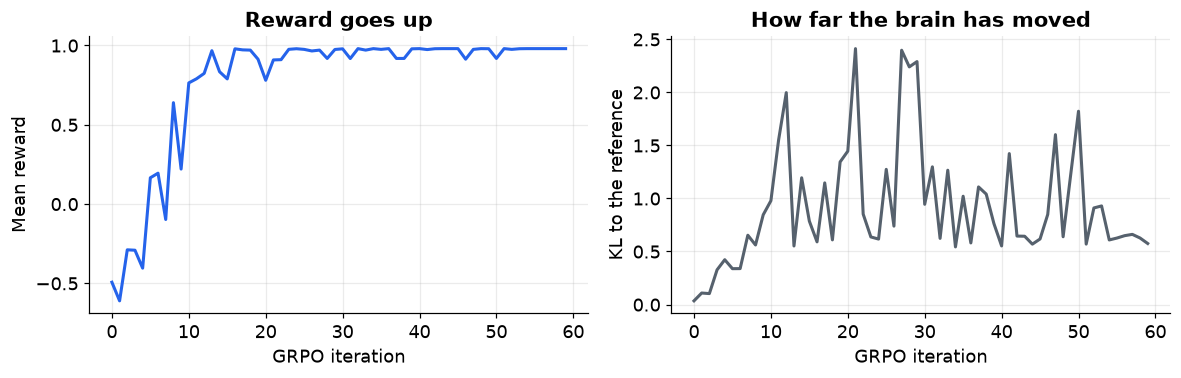

In [18]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(reward_history, color=ACCENT, linewidth=2)
left.set(xlabel="GRPO iteration", ylabel="Mean reward", title="Reward goes up")
right.plot(kl_history, color="#56616D", linewidth=2)
right.set(xlabel="GRPO iteration", ylabel="KL to the reference", title="How far the brain has moved")
for ax in (left, right):
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**What just happened?** The mean reward climbs toward the best possible score, **+0.98** (one useful tool for −0.02, then Finish for +1). Meanwhile the KL rises: the agent accepts a small leash penalty to move away from its random starting brain.

## 11 · Did it learn to read? 🏆

These questions were **never seen in practice**, and some contain words that aren't in the vocabulary.

In [19]:
after = test_accuracy(policy, test_tasks)
print(f"Before: {before:.0%} | After: {after:.0%}\n")
for task in test_tasks:
    attempt = play(policy, task, greedy=True)
    path = " → ".join(buttons[a] for a in attempt["actions"])
    print(f"{task[1]:24} {path:22} {'✅' if attempt['success'] else '❌'}")

Before: 18% | After: 98%

What is 9 x 11?          Calculator → Finish    ✅
Calculate 4 times 25     Calculator → Finish    ✅
Define gravity           Dictionary → Finish    ✅
What does comet mean?    Dictionary → Finish    ✅
Say bye to my friend     Reply → Finish         ✅
Say thanks               Reply → Finish         ✅


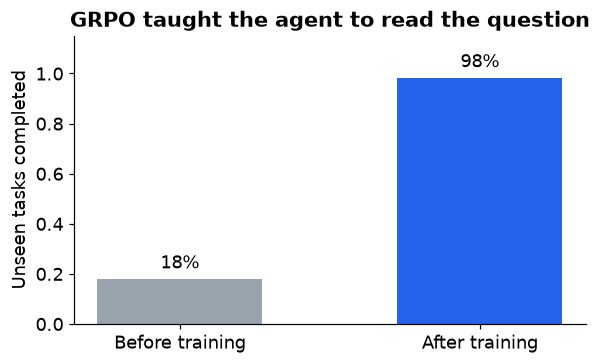

In [20]:
plt.figure(figsize=(6, 3.4))
bars = plt.bar(["Before training", "After training"], [before, after], color=[GREY, ACCENT], width=0.55)
plt.bar_label(bars, labels=[f"{before:.0%}", f"{after:.0%}"], padding=4, fontsize=12)
plt.ylim(0, 1.15)
plt.ylabel("Unseen tasks completed")
plt.title("GRPO taught the agent to read the question")
plt.show()

**What just happened?** The agent now picks the right tool for new phrasings such as *"Calculate 4 times 25"* and *"What does comet mean?"*. It reads the useful words and ignores the unknown ones.

## 12 · Experiments: what does each GRPO knob do? 🧪

We train fresh agents with different settings and compare them on the unseen questions. RL is noisy, so we train **5 agents (seeds) per setting** and report both the **average** and the **worst** agent. This takes about 2 minutes.

In [21]:
def train_grpo(G=8, beta=0.02, clip=0.2, lr=0.01, epochs=4, iterations=60, seed=0):
    random.seed(seed)
    torch.manual_seed(seed)
    policy = TinyPolicy(len(vocab))
    reference = copy.deepcopy(policy).requires_grad_(False)
    optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    for _ in range(iterations):
        batch = collect_batch(policy, random.sample(practice, 4), G)
        grpo_update(policy, reference, optimizer, batch, epochs, clip, beta)
    return policy

settings = {
    "default (G=8)": {},
    "small group (G=2)": {"G": 2},
    "big group (G=16)": {"G": 16},
    "no leash (beta=0)": {"beta": 0.0},
    "tight leash (beta=1)": {"beta": 1.0},
    "big steps, clipped": {"lr": 0.05, "epochs": 10},
    "big steps, NO clip": {"lr": 0.05, "epochs": 10, "clip": 100.0},
}
results = {}
for name, kwargs in settings.items():
    scores = [test_accuracy(train_grpo(seed=s, **kwargs), test_tasks, 20) for s in range(5)]
    results[name] = scores
    print(f"{name:22} average {statistics.mean(scores):4.0%} | worst {min(scores):4.0%}")

default (G=8)          average  96% | worst  90%


small group (G=2)      average  95% | worst  84%


big group (G=16)       average  99% | worst  98%


no leash (beta=0)      average  99% | worst  98%


tight leash (beta=1)   average  50% | worst  42%


big steps, clipped     average  89% | worst  56%


big steps, NO clip     average  85% | worst  55%


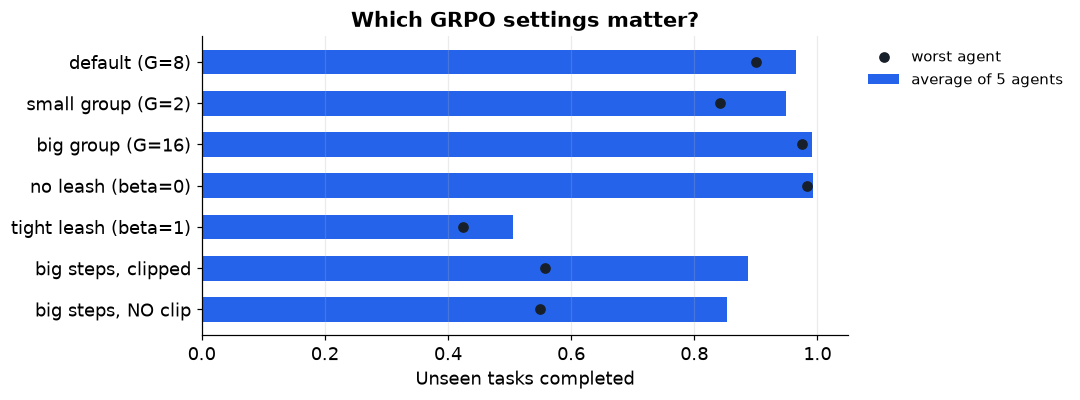

In [22]:
names = list(results)[::-1]
plt.figure(figsize=(10, 3.8))
plt.barh(names, [statistics.mean(results[n]) for n in names], color=ACCENT, height=0.6, label="average of 5 agents")
plt.scatter([min(results[n]) for n in names], names, color="#17202A", zorder=3, s=36, label="worst agent")
plt.xlim(0, 1.05)
plt.xlabel("Unseen tasks completed")
plt.title("Which GRPO settings matter?")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=10, frameon=False)
plt.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.show()

**What you'll typically see** (exact numbers vary between runs, which is normal in RL):

- **A tight leash (`beta=1`) blocks learning.** The agent keeps getting pulled back to its random starting brain. This is the clearest effect.
- **Big steps hurt, and clipping is a safety belt, not a cure.** With a 5× higher learning rate and 10 epochs per batch, agents become less reliable. Clipping usually softens the damage a little: in our runs the clipped version averaged a few points higher. A learning rate that is far too high still fails either way.
- **Bigger groups help a little.** With `G=2` there are only two attempts to compare, so the advantages are noisier.
- **No leash (`beta=0`) is fine here.** This toy has a clear right answer, which is also why recent LLM recipes often drop the KL term.

These are the knobs you'll find in real LLM training configs: `num_generations` (G), `beta`, `epsilon` (clip) and `learning_rate`.

## 13 · From toy GRPO to LLM GRPO 🚀

| In this notebook | In Chapter 4 (a real LLM) |
|:--|:--|
| Question text → word ids | Prompt → tokenizer → token ids |
| `TinyPolicy` (~1,000 numbers) | Qwen2.5-0.5B-Instruct (~500 million numbers) |
| One decision = one button | One decision = one **token** |
| An episode = a few buttons | An episode = a whole answer, including **tool calls** |
| A group of 8 attempts | 8 sampled answers to the same prompt |
| Reward from the world | Reward = **is the final number correct?** |
| Frozen `reference` copy | The original model, with its adapters switched off |

There's one genuinely new problem in Chapter 4. When the LLM calls a tool, the tool's output is pasted into the text. Those words were written **by the tool, not the model**, so we must not train on them. A **loss mask** takes care of that.

## 🎓 Congratulations: you built GRPO from scratch!

- ✅ **Compare a group:** judge attempts against each other; no critic network needed.
- ✅ **Small, safe steps:** ratios and clipping let you reuse data without overshooting.
- ✅ **A leash:** stay close to a reference brain, and know when you can drop it.
- ✅ **Reading:** a policy that sees only words can handle new phrasings.

**One-sentence takeaway:** *GRPO makes each attempt compete with its siblings, then nudges the policy toward the winners, carefully.*

### ➡️ Next: [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

<a href="https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⭐ Found this useful? [Star Train Your RL Agent on GitHub](https://github.com/HamedKhosravi99/Train-Your-RL-Agent) so other beginners can find it.